In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/adeelarif007/starbukcs2/starbucks.csv


CSV files found:
/kaggle/input/datasets/adeelarif007/starbukcs2/starbucks.csv

Dataset loaded successfully!
File: /kaggle/input/datasets/adeelarif007/starbukcs2/starbucks.csv

Dataset Shape:
(242, 18)

Column Names:
['Beverage_category', 'Beverage', 'Beverage_prep', 'Calories', ' Total Fat (g)', 'Trans Fat (g) ', 'Saturated Fat (g)', ' Sodium (mg)', ' Total Carbohydrates (g) ', 'Cholesterol (mg)', ' Dietary Fibre (g)', ' Sugars (g)', ' Protein (g) ', 'Vitamin A (% DV) ', 'Vitamin C (% DV)', ' Calcium (% DV) ', 'Iron (% DV) ', 'Caffeine (mg)']

First 5 Rows:


,Beverage_category,Beverage,Beverage_prep,Calories,Total Fat (g),Trans Fat (g),Saturated Fat (g),Sodium (mg),Total Carbohydrates (g),Cholesterol (mg),Dietary Fibre (g),Sugars (g),Protein (g),Vitamin A (% DV),Vitamin C (% DV),Calcium (% DV),Iron (% DV),Caffeine (mg)
0,Coffee,Brewed Coffee,Short,3,0.1,0.0,0.0,0,5,0,0,0,0.3,0%,0%,0%,0%,175
1,Coffee,Brewed Coffee,Tall,4,0.1,0.0,0.0,0,10,0,0,0,0.5,0%,0%,0%,0%,260
2,Coffee,Brewed Coffee,Grande,5,0.1,0.0,0.0,0,10,0,0,0,1.0,0%,0%,0%,0%,330
3,Coffee,Brewed Coffee,Venti,5,0.1,0.0,0.0,0,10,0,0,0,1.0,0%,0%,2%,0%,410
4,Classic Espresso Drinks,Caffè Latte,Short Nonfat Milk,70,0.1,0.1,0.0,5,75,10,0,9,6.0,10%,0%,20%,0%,75



Categorical Columns:
['Beverage_category', 'Beverage', 'Beverage_prep', ' Total Fat (g)', 'Vitamin A (% DV) ', 'Vitamin C (% DV)', ' Calcium (% DV) ', 'Iron (% DV) ', 'Caffeine (mg)']


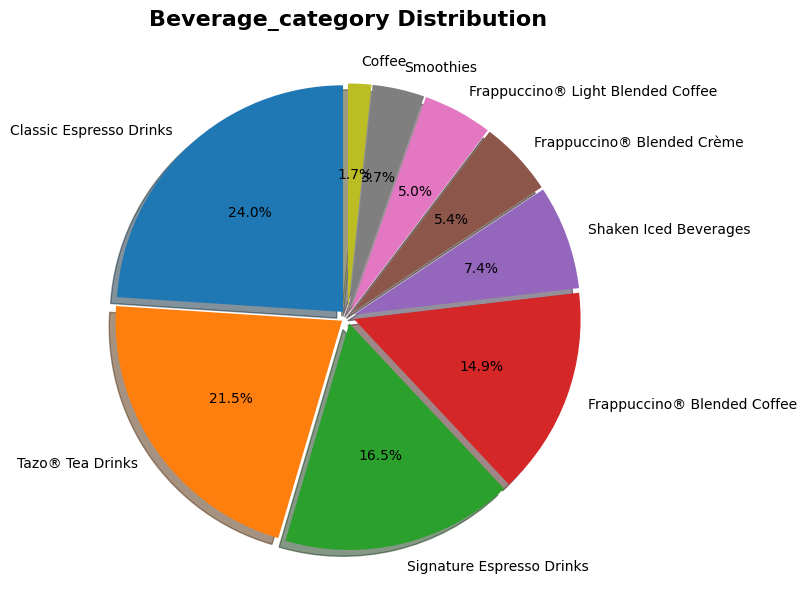

Skipping Beverage: 33 categories
Skipping Beverage_prep: 13 categories
Skipping  Total Fat (g): 24 categories
Skipping Vitamin A (% DV) : 11 categories


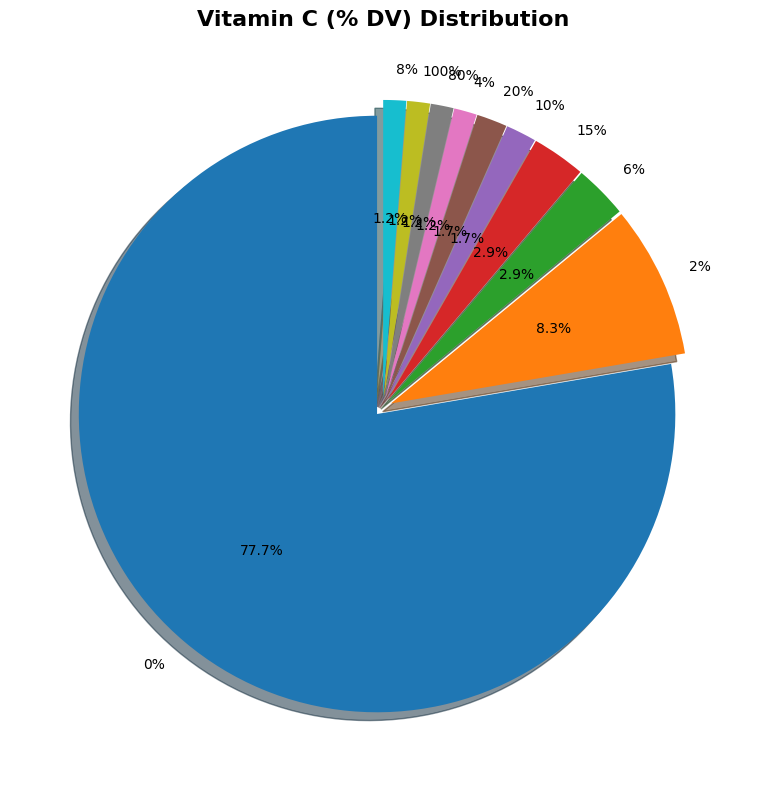

Skipping  Calcium (% DV) : 14 categories
Skipping Iron (% DV) : 18 categories
Skipping Caffeine (mg): 37 categories

Numerical Columns:
['Calories', 'Trans Fat (g) ', 'Saturated Fat (g)', ' Sodium (mg)', ' Total Carbohydrates (g) ', 'Cholesterol (mg)', ' Dietary Fibre (g)', ' Sugars (g)', ' Protein (g) ']

EDA PIE CHART ANALYSIS COMPLETE
Rows: 242
Columns: 18
Categorical columns: 9
Numerical columns: 9


In [2]:
# ============================================
# KAGGLE CSV - PIE CHART EDA
# ============================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

# ============================================
# 1. Find CSV files
# ============================================

csv_files = []

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        if filename.endswith('.csv'):
            csv_files.append(os.path.join(dirname, filename))

print("CSV files found:")
for file in csv_files:
    print(file)


# ============================================
# 2. Load CSV
# ============================================

if len(csv_files) == 0:
    print("No CSV file found!")
else:
    file_path = csv_files[0]

    df = pd.read_csv(file_path)

    print("\nDataset loaded successfully!")
    print("File:", file_path)


    # ========================================
    # 3. Basic information
    # ========================================

    print("\nDataset Shape:")
    print(df.shape)

    print("\nColumn Names:")
    print(df.columns.tolist())

    print("\nFirst 5 Rows:")
    display(df.head())


    # ========================================
    # 4. Find categorical columns
    # ========================================

    categorical_columns = df.select_dtypes(
        include=['object', 'category', 'bool']
    ).columns

    print("\nCategorical Columns:")
    print(categorical_columns.tolist())


    # ========================================
    # 5. Create pie charts
    # ========================================

    for column in categorical_columns:

        counts = df[column].value_counts(dropna=False)

        # Skip columns with more than 10 categories
        if len(counts) > 10:
            print(
                f"Skipping {column}: "
                f"{len(counts)} categories"
            )
            continue

        # Convert labels to strings
        labels = counts.index.astype(str)

        # Replace nan with Missing
        labels = [
            "Missing" if label == "nan" else label
            for label in labels
        ]

        plt.figure(figsize=(8, 8))

        plt.pie(
            counts.values,
            labels=labels,
            autopct='%1.1f%%',
            startangle=90,
            shadow=True,
            explode=[0.03] * len(counts)
        )

        plt.title(
            f"{column} Distribution",
            fontsize=16,
            fontweight='bold'
        )

        plt.tight_layout()
        plt.show()


    # ========================================
    # 6. Numerical columns
    # ========================================

    numerical_columns = df.select_dtypes(
        include=np.number
    ).columns

    print("\nNumerical Columns:")
    print(numerical_columns.tolist())


    # ========================================
    # 7. Summary
    # ========================================

    print("\n================================")
    print("EDA PIE CHART ANALYSIS COMPLETE")
    print("================================")

    print("Rows:", df.shape[0])
    print("Columns:", df.shape[1])
    print(
        "Categorical columns:",
        len(categorical_columns)
    )
    print(
        "Numerical columns:",
        len(numerical_columns)
    )


Dataset Shape: (242, 18)

Columns:
['Beverage_category', 'Beverage', 'Beverage_prep', 'Calories', 'Total Fat (g)', 'Trans Fat (g)', 'Saturated Fat (g)', 'Sodium (mg)', 'Total Carbohydrates (g)', 'Cholesterol (mg)', 'Dietary Fibre (g)', 'Sugars (g)', 'Protein (g)', 'Vitamin A (% DV)', 'Vitamin C (% DV)', 'Calcium (% DV)', 'Iron (% DV)', 'Caffeine (mg)']

Missing values after cleaning:
Beverage_category          0
Beverage                   0
Beverage_prep              0
Calories                   0
Total Fat (g)              0
Trans Fat (g)              0
Saturated Fat (g)          0
Sodium (mg)                0
Total Carbohydrates (g)    0
Cholesterol (mg)           0
Dietary Fibre (g)          0
Sugars (g)                 0
Protein (g)                0
Vitamin A (% DV)           0
Vitamin C (% DV)           0
Calcium (% DV)             0
Iron (% DV)                0
Caffeine (mg)              0
dtype: int64

Features Shape: (242, 59)
Target Classes: 9

Training samples: 193
Testing sa

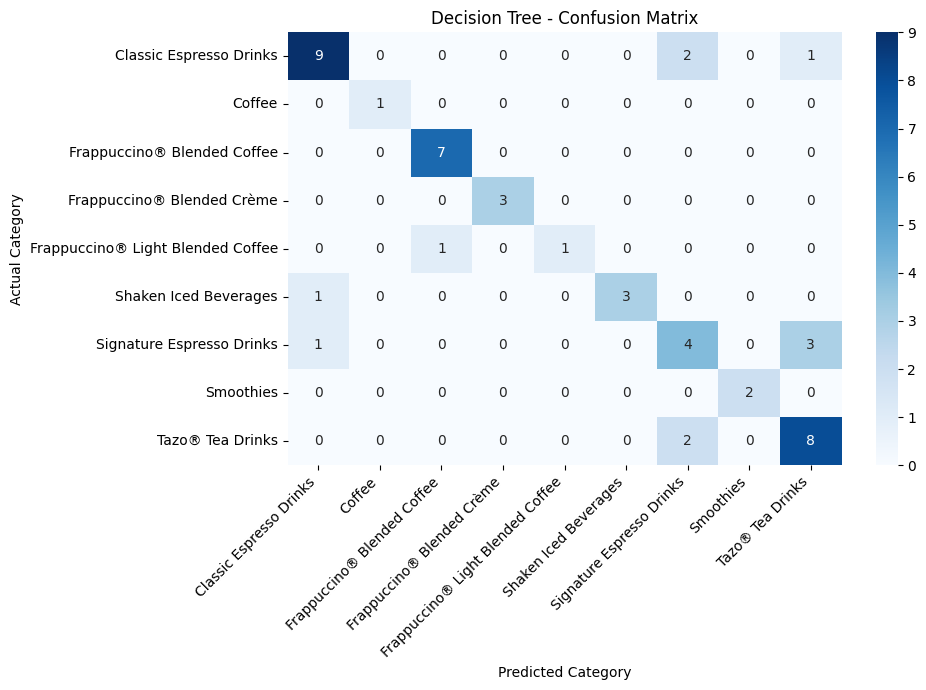


Top 10 Important Features:
                                              Feature  Importance
8                                          Sugars (g)    0.230628
14                                      Caffeine (mg)    0.171058
12                                     Calcium (% DV)    0.127969
5                             Total Carbohydrates (g)    0.117905
9                                         Protein (g)    0.069193
2                                       Trans Fat (g)    0.062931
45  Beverage_Vanilla Latte (Or Other Flavoured Latte)    0.059340
11                                   Vitamin C (% DV)    0.055576
18       Beverage_Caffè Mocha (Without Whipped Cream)    0.055229
6                                    Cholesterol (mg)    0.043567


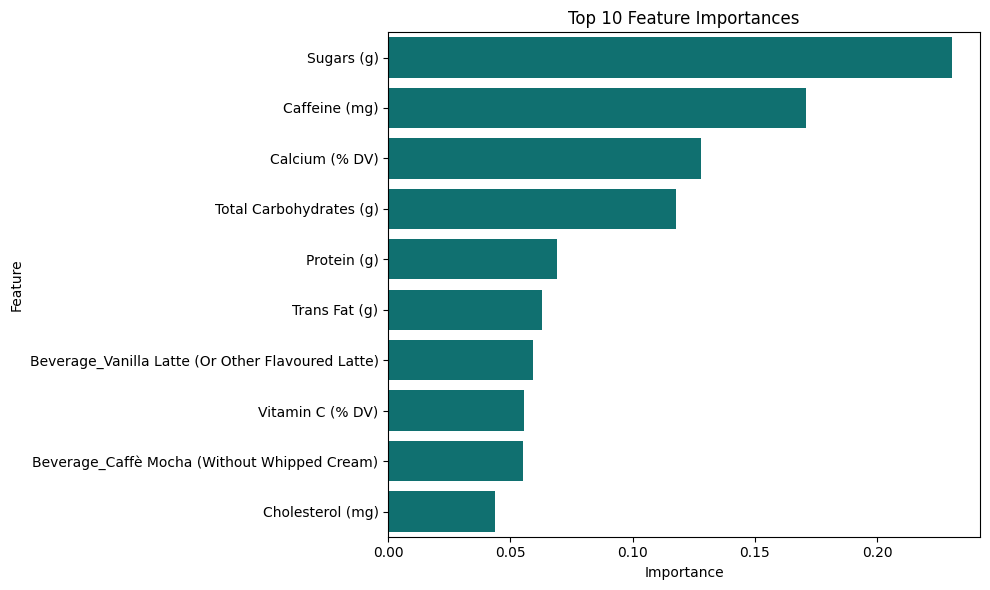

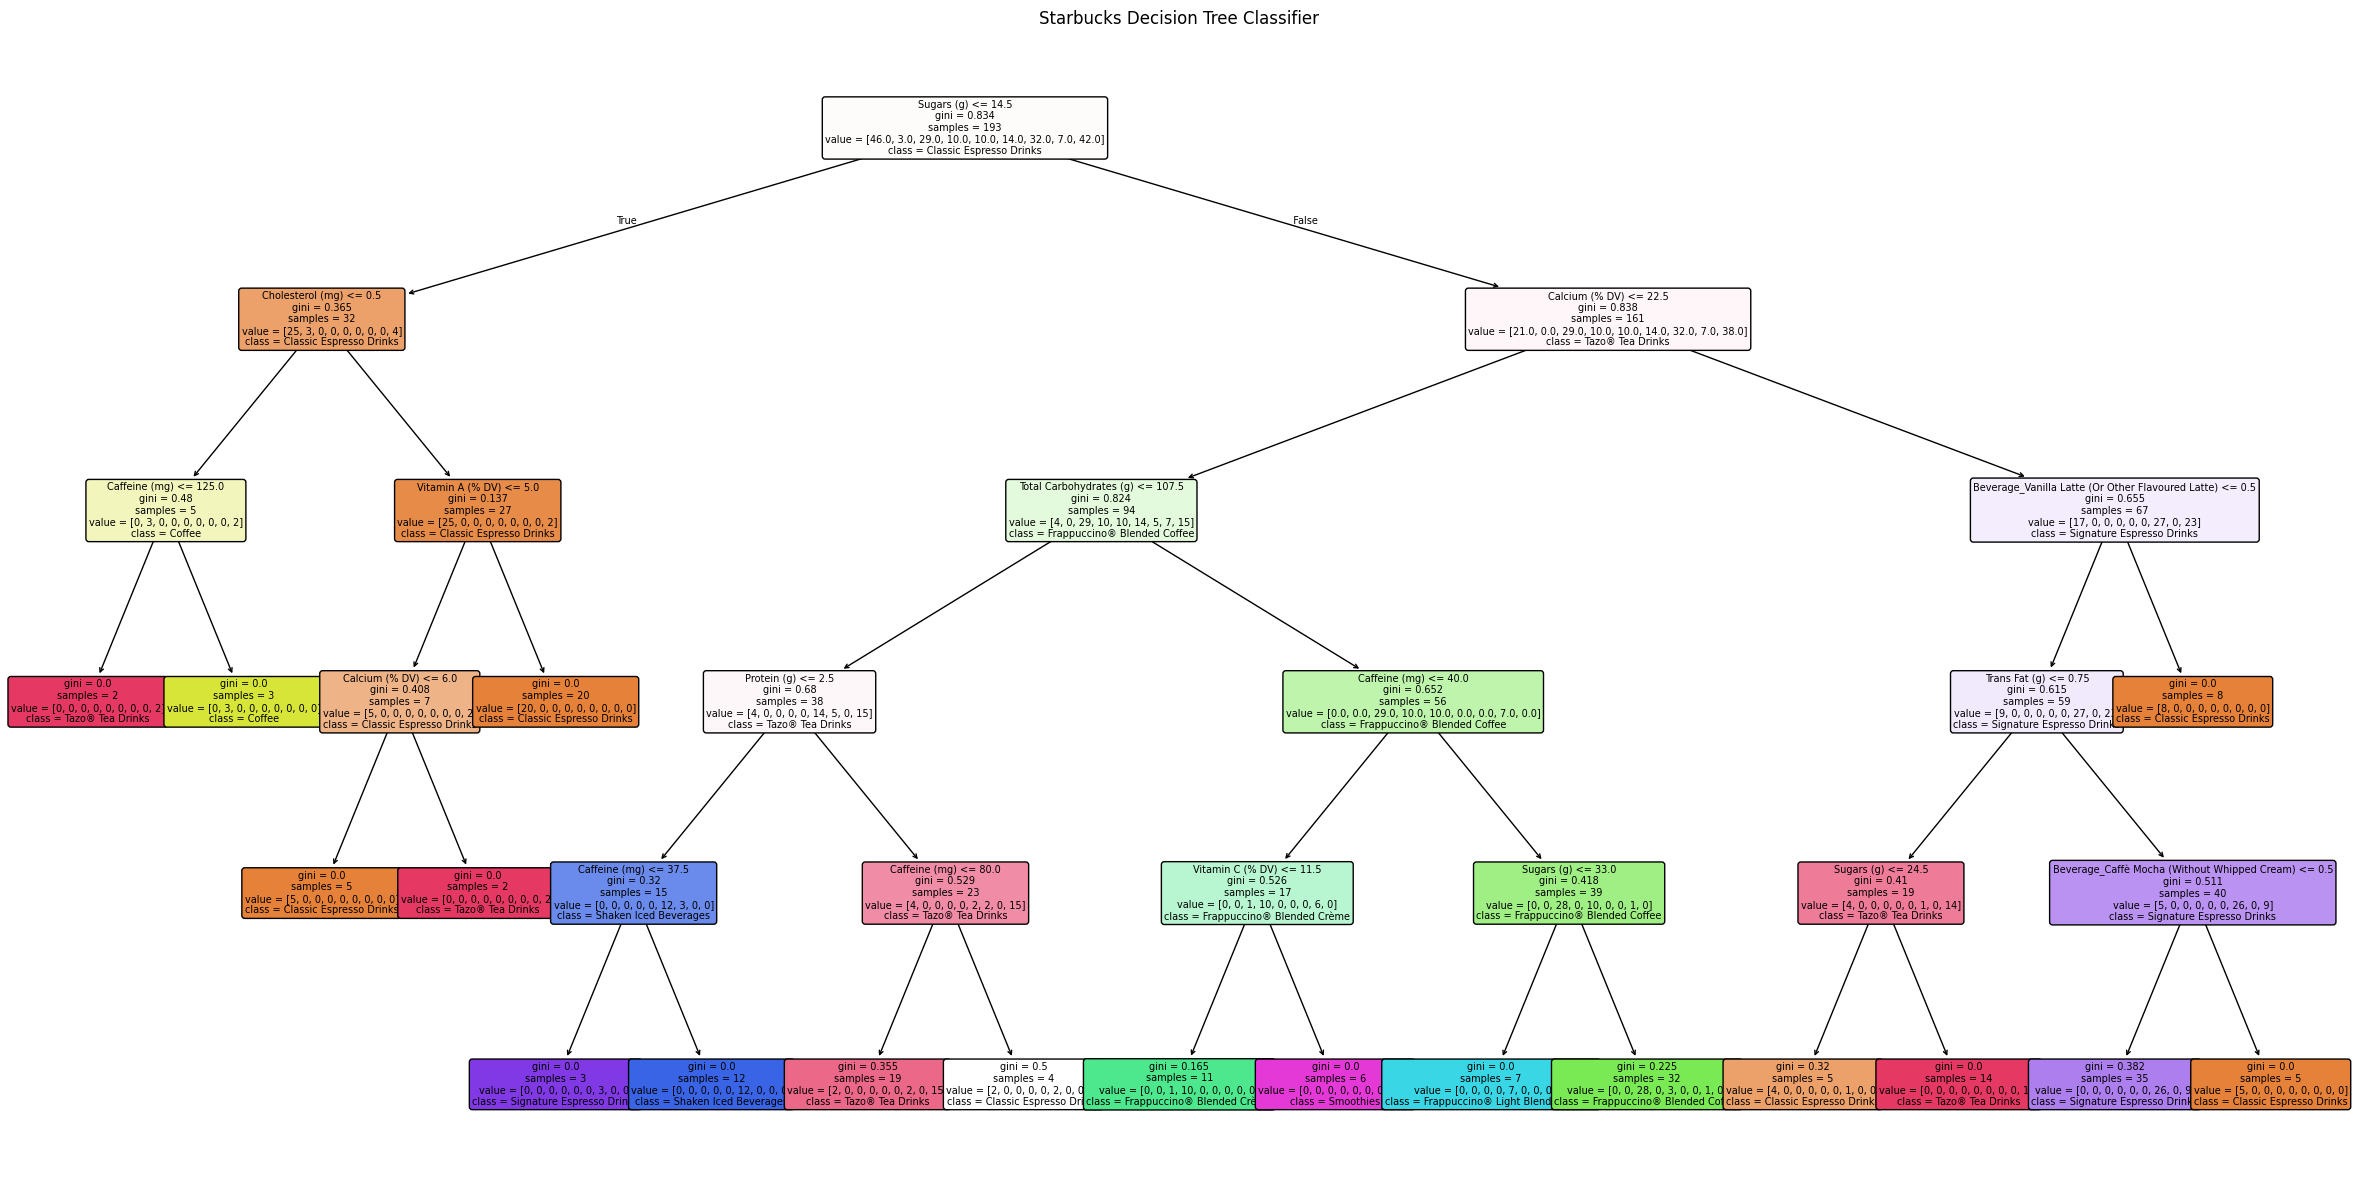


Sample Predictions:
               Actual Category           Predicted Category
0  Frappuccino® Blended Coffee  Frappuccino® Blended Coffee
1    Signature Espresso Drinks             Tazo® Tea Drinks
2      Classic Espresso Drinks      Classic Espresso Drinks
3      Classic Espresso Drinks      Classic Espresso Drinks
4             Tazo® Tea Drinks             Tazo® Tea Drinks
5      Classic Espresso Drinks    Signature Espresso Drinks
6      Classic Espresso Drinks      Classic Espresso Drinks
7        Shaken Iced Beverages        Shaken Iced Beverages
8                       Coffee                       Coffee
9    Signature Espresso Drinks             Tazo® Tea Drinks


In [3]:

# =========================================
# 1. IMPORT LIBRARIES
# =========================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# =========================================
# 2. LOAD DATASET
# =========================================
path = '/kaggle/input/datasets/adeelarif007/starbukcs2/starbucks.csv'

df = pd.read_csv(path)

# Remove extra spaces from column names
df.columns = df.columns.str.strip()

print("Dataset Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

# =========================================
# 3. DATA CLEANING
# =========================================

# Convert percentage columns to numbers
percent_cols = [
    'Vitamin A (% DV)',
    'Vitamin C (% DV)',
    'Calcium (% DV)',
    'Iron (% DV)'
]

for col in percent_cols:
    df[col] = pd.to_numeric(
        df[col].astype(str).str.replace('%', '', regex=False),
        errors='coerce'
    )

# Convert numeric columns that may be stored as text
numeric_cols_to_fix = [
    'Total Fat (g)',
    'Caffeine (mg)'
]

for col in numeric_cols_to_fix:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Fill missing numerical values with median
num_cols = df.select_dtypes(include=np.number).columns

for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

# Remove duplicate rows
df = df.drop_duplicates().copy()

print("\nMissing values after cleaning:")
print(df.isnull().sum())

# =========================================
# 4. SELECT TARGET
# =========================================
# Predict the beverage category
target = 'Beverage_category'

X = df.drop(columns=[target])
y = df[target]

# Convert categorical features into numeric features
X = pd.get_dummies(X, drop_first=True)

print("\nFeatures Shape:", X.shape)
print("Target Classes:", y.nunique())

# =========================================
# 5. SPLIT DATA
# =========================================
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

# =========================================
# 6. TRAIN DECISION TREE
# =========================================
model = DecisionTreeClassifier(
    criterion='gini',
    max_depth=5,
    min_samples_split=4,
    min_samples_leaf=2,
    random_state=42
)

model.fit(X_train, y_train)

print("\nDecision Tree Model Trained Successfully!")

# =========================================
# 7. PREDICTIONS
# =========================================
y_pred = model.predict(X_test)

# =========================================
# 8. MODEL EVALUATION
# =========================================
accuracy = accuracy_score(y_test, y_pred)

print("\nModel Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

# =========================================
# 9. CONFUSION MATRIX
# =========================================
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=model.classes_
)

plt.figure(figsize=(10, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

plt.title("Decision Tree - Confusion Matrix")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# =========================================
# 10. FEATURE IMPORTANCE
# =========================================
importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': model.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

print("\nTop 10 Important Features:")
print(importance.head(10))

plt.figure(figsize=(10, 6))
sns.barplot(
    data=importance.head(10),
    x='Importance',
    y='Feature',
    color='teal'
)

plt.title("Top 10 Feature Importances")
plt.tight_layout()
plt.show()

# =========================================
# 11. VISUALIZE DECISION TREE
# =========================================
plt.figure(figsize=(24, 12))

plot_tree(
    model,
    feature_names=X.columns.tolist(),
    class_names=[str(c) for c in model.classes_],
    filled=True,
    rounded=True,
    fontsize=7
)

plt.title("Starbucks Decision Tree Classifier")
plt.tight_layout()
plt.show()

# =========================================
# 12. SAMPLE PREDICTIONS
# =========================================
results = pd.DataFrame({
    'Actual Category': y_test.values,
    'Predicted Category': y_pred
})

print("\nSample Predictions:")
print(results.head(10))

In [4]:
# Predict categories for test data
y_pred = model.predict(X_test)

# Compare actual and predicted results
prediction_results = pd.DataFrame({
    'Actual Category': y_test.values,
    'Predicted Category': y_pred
})

print("First 15 Predictions:")
print(prediction_results.head(15))

# Save predictions to CSV
prediction_results.to_csv(
    '/kaggle/working/starbucks_predictions.csv',
    index=False
)

print("\nPredictions saved successfully!")

# =========================================
# CHECK CORRECT AND INCORRECT PREDICTIONS
# =========================================

prediction_results['Correct Prediction'] = (
    prediction_results['Actual Category']
    == prediction_results['Predicted Category']
)

print("\nCorrect Predictions:")
print(prediction_results['Correct Prediction'].sum())

print("\nIncorrect Predictions:")
print((~prediction_results['Correct Prediction']).sum())

print("\nPrediction Accuracy:")
print(
    round(
        prediction_results['Correct Prediction'].mean() * 100,
        2
    ),
    "%"
)

First 15 Predictions:
                Actual Category           Predicted Category
0   Frappuccino® Blended Coffee  Frappuccino® Blended Coffee
1     Signature Espresso Drinks             Tazo® Tea Drinks
2       Classic Espresso Drinks      Classic Espresso Drinks
3       Classic Espresso Drinks      Classic Espresso Drinks
4              Tazo® Tea Drinks             Tazo® Tea Drinks
5       Classic Espresso Drinks    Signature Espresso Drinks
6       Classic Espresso Drinks      Classic Espresso Drinks
7         Shaken Iced Beverages        Shaken Iced Beverages
8                        Coffee                       Coffee
9     Signature Espresso Drinks             Tazo® Tea Drinks
10      Classic Espresso Drinks      Classic Espresso Drinks
11      Classic Espresso Drinks      Classic Espresso Drinks
12    Signature Espresso Drinks      Classic Espresso Drinks
13  Frappuccino® Blended Coffee  Frappuccino® Blended Coffee
14      Classic Espresso Drinks      Classic Espresso Drinks

P

In [5]:
import joblib
import os

# Folder for saved files
os.makedirs('/kaggle/working', exist_ok=True)

# Prepare model bundle
target = 'Beverage_category'

bundle = {
    'model': model,
    'feature_columns': X.columns.tolist(),
    'raw_feature_columns': df.drop(columns=[target]).columns.tolist(),
    'numeric_features': df.drop(columns=[target]).select_dtypes(
        include=np.number
    ).columns.tolist(),
    'numeric_medians': df.drop(columns=[target]).select_dtypes(
        include=np.number
    ).median().to_dict(),
    'beverages': sorted(df['Beverage'].dropna().unique().tolist()),
    'beverage_preps': sorted(
        df['Beverage_prep'].dropna().unique().tolist()
    )
}

# Save model and preprocessing information
save_path = '/kaggle/working/starbucks_decision_tree.joblib'

joblib.dump(bundle, save_path)

print("Model saved successfully!")
print("File path:", save_path)

# Verify saved file
loaded_bundle = joblib.load(save_path)

print("Model type:", type(loaded_bundle['model']).__name__)
print("Number of features:", len(loaded_bundle['feature_columns']))
print("Target classes:", loaded_bundle['model'].classes_)

Model saved successfully!
File path: /kaggle/working/starbucks_decision_tree.joblib
Model type: DecisionTreeClassifier
Number of features: 59
Target classes: ['Classic Espresso Drinks' 'Coffee' 'Frappuccino® Blended Coffee'
 'Frappuccino® Blended Crème' 'Frappuccino® Light Blended Coffee'
 'Shaken Iced Beverages' 'Signature Espresso Drinks' 'Smoothies'
 'Tazo® Tea Drinks']
